In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_csv("/kaggle/input/datasets/tunguz/online-retail/Online_Retail.csv", encoding="latin1")

print("=== 前5行 ===")
print(df.head())
print("\n=== 数据信息 ===")
print(df.info())
print("\n=== 缺失值 ===")
print(df.isnull().sum())


=== 前5行 ===
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

    InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/10 8:26       2.55     17850.0  United Kingdom  
1  12/1/10 8:26       3.39     17850.0  United Kingdom  
2  12/1/10 8:26       2.75     17850.0  United Kingdom  
3  12/1/10 8:26       3.39     17850.0  United Kingdom  
4  12/1/10 8:26       3.39     17850.0  United Kingdom  

=== 数据信息 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 复制一份，不改动原始df
df_clean = df.copy()

# 1. 日期转为datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 2. 新增订单总金额 = 数量 * 单价
df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

# 3. 提取年、月、日、小时，方便后续分析
df_clean['Year'] = df_clean['InvoiceDate'].dt.year
df_clean['Month'] = df_clean['InvoiceDate'].dt.month
df_clean['Day'] = df_clean['InvoiceDate'].dt.day
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

# 4. 过滤：去掉数量<=0、单价<=0的退货/异常数据
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# 查看清洗后信息
print("清洗后数据量：", df_clean.shape)
print("\n前5行：")
print(df_clean.head())
print("\n统计描述：")
print(df_clean[['Quantity','UnitPrice','TotalAmount']].describe())


/tmp/ipykernel_16/403273949.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])


清洗后数据量： (530104, 13)

前5行：
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalAmount  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom        15.30   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom        22.00   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34   

   Year  Month  Day  Hour  
0  2010     12    1     8  
1  2010     12    1  

In [3]:
# ===== 核心经营指标 =====
total_sales = df_clean["TotalAmount"].sum()
total_orders = df_clean["InvoiceNo"].nunique()
total_items = len(df_clean)

# 客户级分析：先去掉空 CustomerID
df_cust = df_clean.dropna(subset=["CustomerID"]).copy()
total_customers = df_cust["CustomerID"].nunique()

# 复购：下单 ≥ 2 次的客户
order_per_cust = df_cust.groupby("CustomerID")["InvoiceNo"].nunique()
repeat = (order_per_cust >= 2).sum()
repurchase_rate = repeat / total_customers

print(f"总销售额: £{total_sales:,.2f}")
print(f"订单数: {total_orders}")
print(f"商品行项目数: {total_items}")
print(f"有记录客户数: {total_customers}")
print(f"复购客户数: {repeat}")
print(f"复购率: {repurchase_rate:.1%}")


总销售额: £10,666,684.54
订单数: 19960
商品行项目数: 530104
有记录客户数: 4338
复购客户数: 2845
复购率: 65.6%


In [4]:
# 1. 月度销售额趋势
monthly = df_clean.groupby(df_clean["InvoiceDate"].dt.to_period("M"))["TotalAmount"].sum()
print("=== 月度销售额 ===")
print(monthly.round(2))

# 2. 各国销售额 TOP10
country = df_clean.groupby("Country")["TotalAmount"].sum().sort_values(ascending=False).head(10)
print("\n=== 各国销售额 TOP10 ===")
print(country.round(2))

# 3. 热销商品 TOP10（按销量）
top_products = df_clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
print("\n=== 热销商品 TOP10 ===")
print(top_products)


=== 月度销售额 ===
InvoiceDate
2010-12     823746.14
2011-01     691364.56
2011-02     523631.89
2011-03     717639.36
2011-04     537808.62
2011-05     770536.02
2011-06     761739.90
2011-07     719221.19
2011-08     759138.38
2011-09    1058590.17
2011-10    1154979.30
2011-11    1509496.33
2011-12     638792.68
Freq: M, Name: TotalAmount, dtype: float64

=== 各国销售额 TOP10 ===
Country
United Kingdom    9025222.08
Netherlands        285446.34
EIRE               283453.96
Germany            228867.14
France             209715.11
Australia          138521.31
Spain               61577.11
Switzerland         57089.90
Belgium             41196.34
Sweden              38378.33
Name: TotalAmount, dtype: float64

=== 热销商品 TOP10 ===
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
POPCORN HOLDER                        36

findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of 

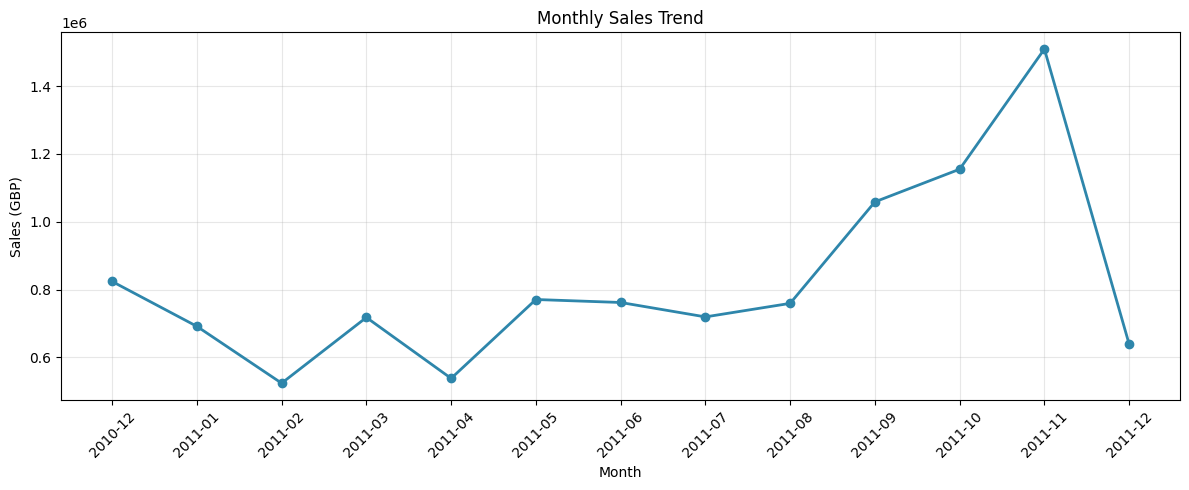

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['WenQuanYi Zen Hei']
plt.rcParams['axes.unicode_minus'] = False

monthly = df_clean.groupby(df_clean["InvoiceDate"].dt.to_period("M"))["TotalAmount"].sum()
monthly.index = monthly.index.astype(str)

plt.figure(figsize=(12,5))
plt.plot(monthly.index, monthly.values, marker='o', color='#2E86AB', linewidth=2)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (GBP)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of 

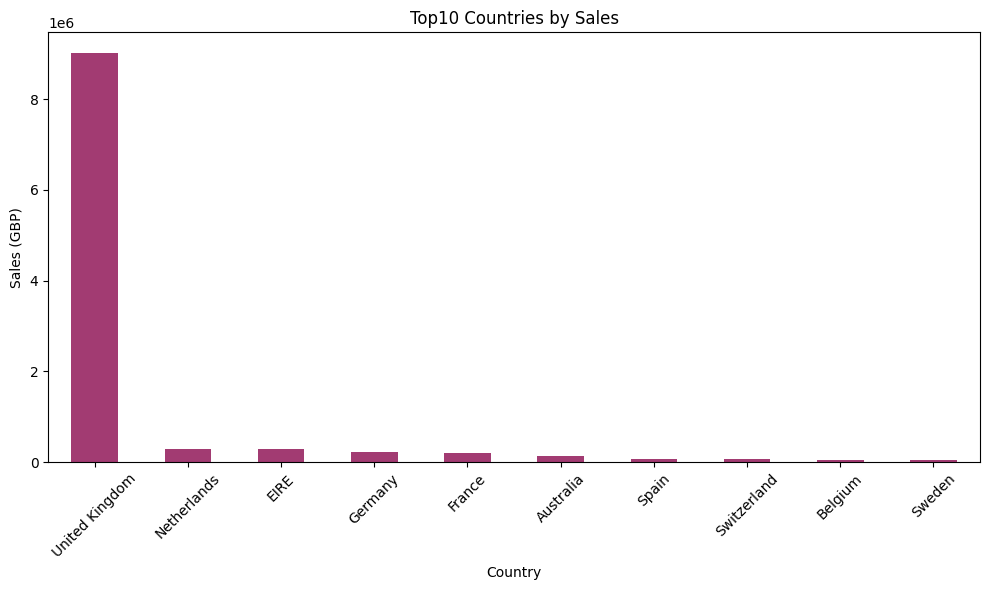

In [6]:
country_sales = df_clean.groupby("Country")["TotalAmount"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,6))
country_sales.plot(kind="bar", color="#A23B72")
plt.title("Top10 Countries by Sales")
plt.xlabel("Country")
plt.ylabel("Sales (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [7]:
# 只保留有CustomerID的数据
df_rfm = df_clean.dropna(subset=["CustomerID"]).copy()

# 订单时间取最大值作为基准时间
snapshot_date = df_rfm["InvoiceDate"].max()

# 计算RFM
rfm = df_rfm.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

# 分箱打分 1-5分，5最好
rfm["R_score"] = pd.qcut(rfm["Recency"], 5, labels=[5,4,3,2,1])
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"),5, labels=[1,2,3,4,5])
rfm["M_score"] = pd.qcut(rfm["Monetary"],5, labels=[1,2,3,4,5])

# 合并RFM标签
rfm["RFM_Segment"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)

print(rfm.head())
print("\n==== 用户分层统计 ====")
print(rfm["RFM_Segment"].value_counts().head(10))


   CustomerID  Recency  Frequency  Monetary R_score F_score M_score  \
0     12346.0      325          1  77183.60       1       1       5   
1     12347.0        1          7   4310.00       5       5       5   
2     12348.0       74          4   1797.24       2       4       4   
3     12349.0       18          1   1757.55       4       1       4   
4     12350.0      309          1    334.40       1       1       2   

  RFM_Segment  
0         115  
1         555  
2         244  
3         414  
4         112  

==== 用户分层统计 ====
RFM_Segment
555    348
111    183
455    178
121    153
112    128
444    122
122     92
544     88
233     85
344     83
Name: count, dtype: int64


In [8]:
def rfm_label(row):
    r, f, m = int(row['R_score']), int(row['F_score']), int(row['M_score'])
    if r == 5 and f == 5 and m == 5:
        return "Core High-Value"
    elif r <= 2 and f >= 4 and m >=4:
        return "Dormant High-Value"
    elif r >=4 and f <=2 and m <=2:
        return "New / One-time"
    elif r <=2 and f <=2 and m <=2:
        return "Churned Low-Value"
    elif r >=4 and f >=3 and m >=3:
        return "Potential User"
    else:
        return "General User"

rfm['Segment_Label'] = rfm.apply(rfm_label, axis=1)
print(rfm['Segment_Label'].value_counts())


Segment_Label
General User          1815
Potential User         951
Churned Low-Value      824
Core High-Value        348
New / One-time         234
Dormant High-Value     166
Name: count, dtype: int64


findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of the following families were found: WenQuanYi Zen Hei
findfont: Generic family 'sans-serif' not found because none of 

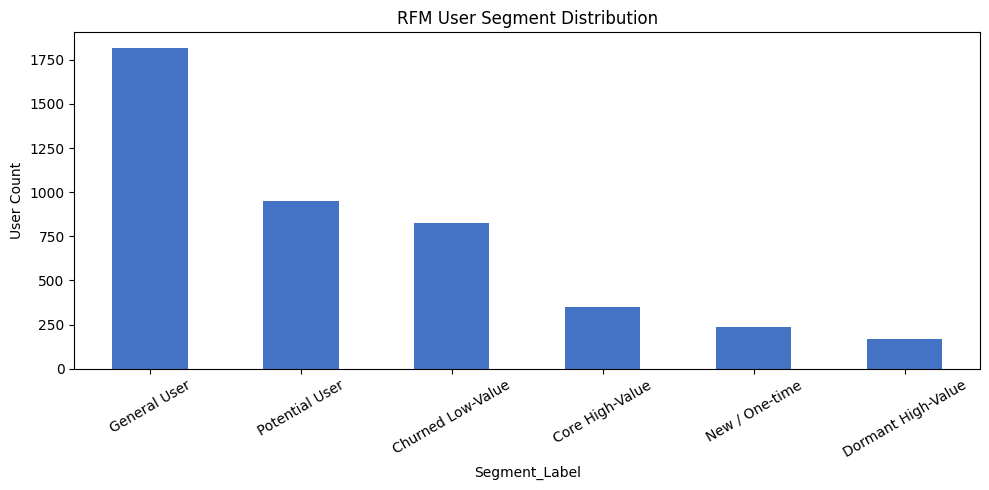

In [9]:
seg_count = rfm['Segment_Label'].value_counts()
plt.figure(figsize=(10,5))
seg_count.plot(kind='bar',color='#4472C4')
plt.title("RFM User Segment Distribution")
plt.ylabel("User Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
